# Traditional models: training, evaluation, and resource measurement

Run Notebook 03 first. This notebook compares Logistic Regression, Random Forest, and XGBoost on the validated and significant prepared datasets. Config A uses per-version features, Config B uses paired differences, and the combined configuration remains available. Each dataset uses problem-grouped cross-validation, with groups held out between training and validation. The selected feature configurations remain Config B for validated data and combined features for significant data. Predictive evaluation and separate training/inference resource measurements run in this notebook. Benchmark measurements define the target and are never supplied as model features. CodeBERT is handled only in Notebook 05.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run 03_feature_engineering.ipynb first to create Data/Processed.")
PROCESSED_DIR = ROOT / "Data" / "Processed"
RESULTS_DIR = ROOT / "Results" / "validated"
MODEL_DIR = PROCESSED_DIR / "models" / "validated"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df_ml_ready = pd.read_parquet(PROCESSED_DIR / "prepared_training_dataset.parquet")
manifest = json.loads((PROCESSED_DIR / "feature_manifest.json").read_text(encoding="utf-8"))
FEATURE_CONFIG_BY_DATASET = {"validated": "config_B", "significant": "combined"}
FEATURE_CONFIG = FEATURE_CONFIG_BY_DATASET["validated"]
feature_config_manifest_keys = {
    "config_A": "per_version",
    "config_B": "differences",
    "combined": "combined",
}
if FEATURE_CONFIG not in feature_config_manifest_keys:
    raise ValueError(f"Unknown feature configuration: {FEATURE_CONFIG}")
config_A_features = manifest["configurations"]["per_version"]
config_B_features = manifest["configurations"]["differences"]
clean_config_A_features = config_A_features
clean_config_B_features = config_B_features
# Materialize each matrix before selecting the configured one.
X_A_clean = df_ml_ready[clean_config_A_features].astype(float)
X_B_clean = df_ml_ready[clean_config_B_features].astype(float)
X_combined = df_ml_ready[manifest["configurations"]["combined"]].astype(float)
feature_matrices = {
    "config_A": X_A_clean,
    "config_B": X_B_clean,
    "combined": X_combined,
}
X = feature_matrices[FEATURE_CONFIG]
y_class = df_ml_ready["energy_winner"].astype(int)
groups = df_ml_ready["group_id"]
if groups.nunique() < 5:
    raise ValueError(f"GroupKFold(5) requires at least 5 problems; found {groups.nunique()}.")
if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
    raise ValueError("Feature matrix contains missing or non-finite values.")
if y_class.nunique() != 2:
    raise ValueError("Binary energy-winner training requires both target classes.")
gkf = GroupKFold(n_splits=5)
print(
    f"Loaded {len(df_ml_ready):,} non-tied pairs from {groups.nunique():,} problems; "
    f"configuration={FEATURE_CONFIG}, features={X.shape[1]}."
)


Loaded 21,410 non-tied pairs from 1,232 problems; configuration=config_B, features=15.


### Grouped cross-validation and final fitted models

All feature configurations use the same GroupKFold splits. Zero-variance features are retained. The selected feature configuration, columns, estimator hyperparameters, and fitted preprocessing pipeline are saved. Selected-configuration fold models and their train/validation problem-group provenance support held-out inference measurements in this same notebook. Accuracy, balanced accuracy, F1, and ROC-AUC are reported.

In [2]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from experiment_utils import train_tabular_configurations

model_factories = {
    "majority_baseline": lambda: DummyClassifier(strategy="most_frequent"),
    "logistic_regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42),
    ),
    "random_forest": lambda: RandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1,
        class_weight="balanced_subsample",
    ),
    "xgboost": lambda: XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42,
        n_jobs=4, eval_metric="logloss",
    ),
}

feature_configurations = {
    "config_A": clean_config_A_features,
    "config_B": clean_config_B_features,
    "combined": manifest["configurations"]["combined"],
}
feature_config_descriptions = {
    "config_A": "per-version static features",
    "config_B": "paired feature differences (V1 - V0)",
    "combined": "Config A plus Config B",
}
performance, fitted_models, fitted_feature_columns = train_tabular_configurations(
    dataset_name="validated",
    frame=df_ml_ready,
    feature_configurations=feature_configurations,
    model_factories=model_factories,
    selected_feature_config=FEATURE_CONFIG_BY_DATASET["validated"],
    results_dir=RESULTS_DIR,
    model_dir=MODEL_DIR,
    save_fold_models=True,
)
selected_columns = fitted_feature_columns["logistic_regression"]
(MODEL_DIR / "training_metadata.json").write_text(
    json.dumps({
        "dataset": "validated",
        "feature_config": FEATURE_CONFIG_BY_DATASET["validated"],
        "feature_config_description": feature_config_descriptions[FEATURE_CONFIG_BY_DATASET["validated"]],
        "feature_configurations_evaluated": feature_config_descriptions,
        "feature_columns": selected_columns,
        "target": "energy_winner",
        "group_column": "group_id",
        "group_kfold_splits": 5,
        "fold_model_directory": f"{FEATURE_CONFIG_BY_DATASET['validated']}/fold_models",
        "model_hyperparameters": {
            "logistic_regression": {"scaler": "StandardScaler", "max_iter": 2000, "random_state": 42},
            "random_forest": {"n_estimators": 200, "max_depth": 12, "random_state": 42, "n_jobs": -1, "class_weight": "balanced_subsample"},
            "xgboost": {"n_estimators": 150, "max_depth": 6, "learning_rate": 0.1, "random_state": 42, "n_jobs": 4, "eval_metric": "logloss"},
        },
        "models": list(model_factories),
    }, indent=2),
    encoding="utf-8",
)
display(performance)
print(
    f"Saved all configuration fits under {MODEL_DIR}; "
    f"the selected {FEATURE_CONFIG_BY_DATASET['validated']} models are also available at the dataset root for energy measurement."
)


Evaluating majority_baseline on validated/config_A...
Evaluating logistic_regression on validated/config_A...
Evaluating random_forest on validated/config_A...
Evaluating xgboost on validated/config_A...
Evaluating majority_baseline on validated/config_B...
Evaluating logistic_regression on validated/config_B...
Evaluating random_forest on validated/config_B...
Evaluating xgboost on validated/config_B...
Evaluating majority_baseline on validated/combined...
Evaluating logistic_regression on validated/combined...
Evaluating random_forest on validated/combined...
Evaluating xgboost on validated/combined...


,dataset,model,feature_config,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std
0,validated,logistic_regression,combined,0.594769,0.008016,0.646982,0.007701,0.594661,0.008170,0.570816,0.011073
1,validated,logistic_regression,config_A,0.596217,0.006618,0.647195,0.007953,0.596100,0.006839,0.572105,0.010183
2,validated,logistic_regression,config_B,0.598412,0.007492,0.649325,0.007991,0.598381,0.007732,0.577154,0.008986
3,validated,majority_baseline,combined,0.498225,0.004569,0.500000,0.000000,0.500000,0.000000,0.131872,0.294875
4,validated,majority_baseline,config_A,0.498225,0.004569,0.500000,0.000000,0.500000,0.000000,0.131872,0.294875
5,validated,majority_baseline,config_B,0.498225,0.004569,0.500000,0.000000,0.500000,0.000000,0.131872,0.294875
6,validated,random_forest,combined,0.589351,0.009997,0.642809,0.010033,0.589424,0.010005,0.580641,0.011034
7,validated,random_forest,config_A,0.583652,0.010471,0.626622,0.010082,0.583578,0.010534,0.575910,0.009879
8,validated,random_forest,config_B,0.594535,0.007862,0.647855,0.008774,0.594614,0.007981,0.590463,0.016778
9,validated,xgboost,combined,0.585194,0.011150,0.634292,0.010327,0.585234,0.011184,0.575185,0.009741


Saved all configuration fits under d:\Habiba\Uni\W26\Bachelor Thesis\energy-aware-code-recommendation\Data\Processed\models\validated; the selected config_B models are also available at the dataset root for energy measurement.


### Feature importance

Tree models use their fitted impurity/gain importances; Logistic Regression uses absolute standardized coefficients. These are descriptive full-training fits, while the reported performance remains GroupKFold out-of-fold performance.



Top 20 features: logistic_regression
                    feature importance
          token_count_delta     0.7267
         import_count_delta     0.6953
       ast_node_count_delta     0.4118
  function_call_count_delta     0.1956
       function_count_delta     0.1886
    conditional_count_delta     0.0953
   builtin_call_count_delta     0.0882
cyclomatic_complexity_delta     0.0881
      sort_call_count_delta     0.0730
    nested_loop_depth_delta     0.0699
   recursion_detected_delta     0.0671
                  loc_delta     0.0500
    max_nesting_depth_delta     0.0194
  comprehension_count_delta     0.0186
           loop_count_delta     0.0147


,feature,importance
0,token_count_delta,0.726747
1,import_count_delta,0.695291
2,ast_node_count_delta,0.411840
3,function_call_count_delta,0.195642
4,function_count_delta,0.188589
5,conditional_count_delta,0.095277
6,builtin_call_count_delta,0.088236
7,cyclomatic_complexity_delta,0.088102
8,sort_call_count_delta,0.072979
9,nested_loop_depth_delta,0.069879



Top 20 features: random_forest
                    feature importance
         import_count_delta     0.2185
          token_count_delta     0.1291
       ast_node_count_delta     0.1136
  function_call_count_delta     0.0878
                  loc_delta     0.0826
   builtin_call_count_delta     0.0618
cyclomatic_complexity_delta     0.0496
    conditional_count_delta     0.0404
           loop_count_delta     0.0404
  comprehension_count_delta     0.0359
    max_nesting_depth_delta     0.0355
       function_count_delta     0.0335
    nested_loop_depth_delta     0.0300
      sort_call_count_delta     0.0208
   recursion_detected_delta     0.0207


,feature,importance
0,import_count_delta,0.218508
1,token_count_delta,0.129058
2,ast_node_count_delta,0.113559
3,function_call_count_delta,0.087763
4,loc_delta,0.082555
5,builtin_call_count_delta,0.061761
6,cyclomatic_complexity_delta,0.049559
7,conditional_count_delta,0.040432
8,loop_count_delta,0.040368
9,comprehension_count_delta,0.035931



Top 20 features: xgboost
                    feature importance
         import_count_delta     0.3763
   recursion_detected_delta     0.0664
       ast_node_count_delta     0.0632
          token_count_delta     0.0573
  function_call_count_delta     0.0491
    nested_loop_depth_delta     0.0462
      sort_call_count_delta     0.0422
  comprehension_count_delta     0.0401
cyclomatic_complexity_delta     0.0387
           loop_count_delta     0.0387
   builtin_call_count_delta     0.0381
       function_count_delta     0.0377
                  loc_delta     0.0375
    max_nesting_depth_delta     0.0359
    conditional_count_delta     0.0324


,feature,importance
0,import_count_delta,0.376336
1,recursion_detected_delta,0.066412
2,ast_node_count_delta,0.063217
3,token_count_delta,0.057288
4,function_call_count_delta,0.049144
5,nested_loop_depth_delta,0.046235
6,sort_call_count_delta,0.042160
7,comprehension_count_delta,0.040053
8,cyclomatic_complexity_delta,0.038746
9,loop_count_delta,0.038682


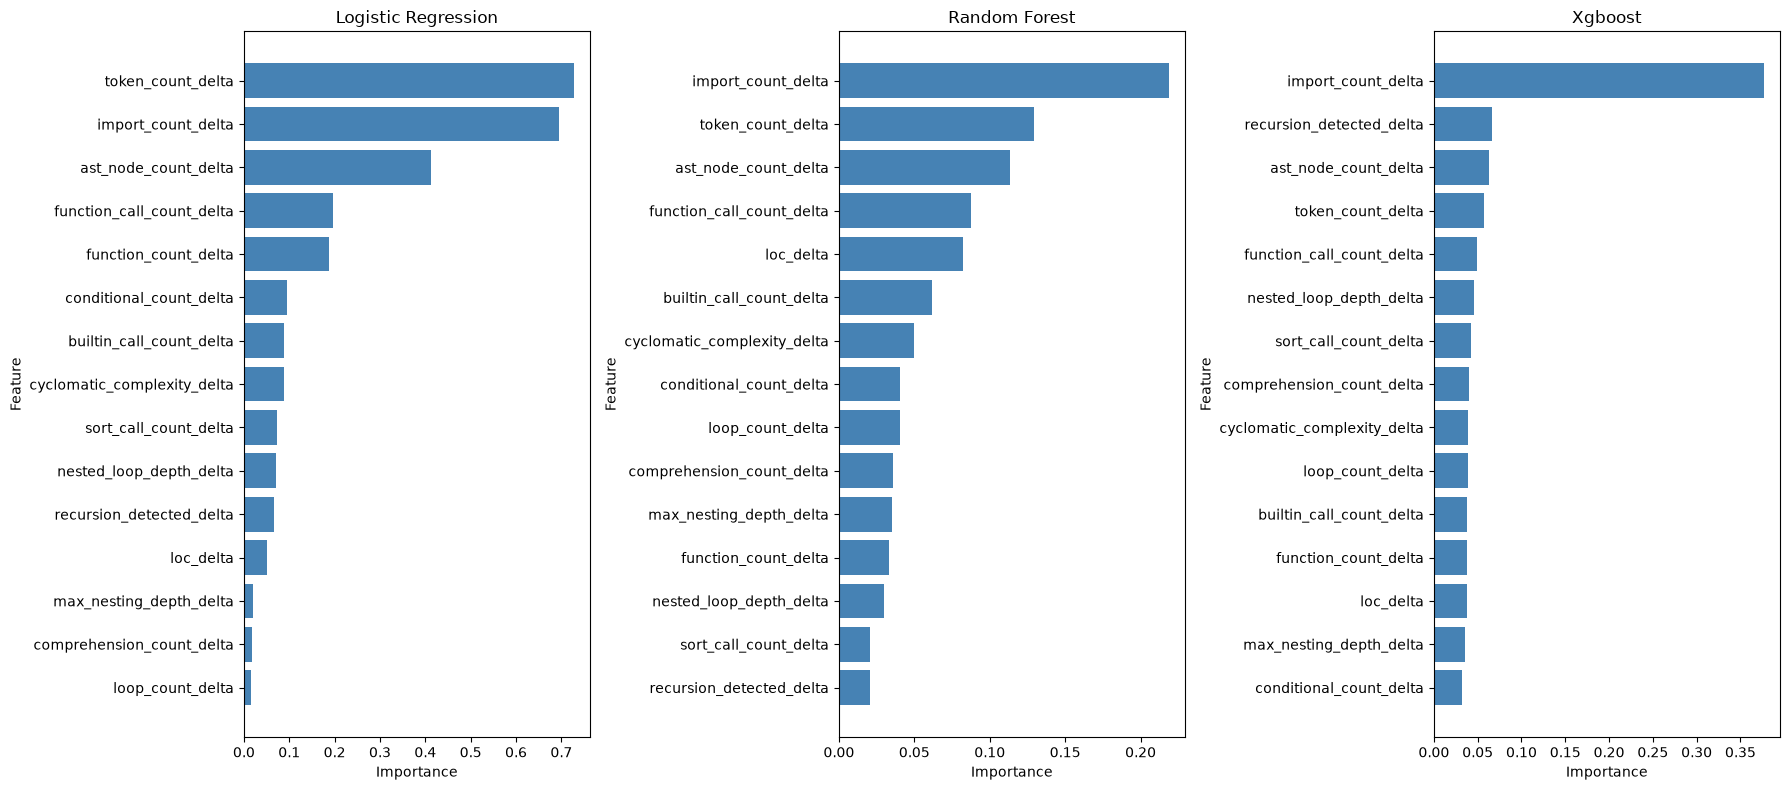

In [3]:
importance_tables = []
for model_name in ("logistic_regression", "random_forest", "xgboost"):
    estimator = fitted_models[model_name]
    if model_name == "logistic_regression":
        classifier = estimator[-1]
        importance = np.abs(classifier.coef_).mean(axis=0)
    else:
        importance = estimator.feature_importances_
    table = pd.DataFrame({"feature": fitted_feature_columns[model_name], "importance": importance})
    table["model"] = model_name
    importance_tables.append(table)

feature_importance = pd.concat(importance_tables, ignore_index=True)
feature_importance.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)
for model_name, table in feature_importance.groupby("model"):
    top_features = table.nlargest(20, "importance")[["feature", "importance"]].reset_index(drop=True)
    print(f"\nTop 20 features: {model_name}")
    print(top_features.to_string(index=False, formatters={"importance": "{:.4f}".format}))
    display(top_features)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, model_name in zip(axes, ("logistic_regression", "random_forest", "xgboost")):
    top = feature_importance[feature_importance["model"] == model_name].nlargest(15, "importance")
    ax.barh(top["feature"], top["importance"], color="steelblue")
    ax.invert_yaxis()
    ax.set(title=model_name.replace("_", " ").title(), xlabel="Importance", ylabel="Feature")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance_top_features.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)



In [4]:
dataset_name = "significant"
significant_results_dir = ROOT / "Results" / dataset_name
significant_model_dir = PROCESSED_DIR / "models" / dataset_name
significant_results_dir.mkdir(parents=True, exist_ok=True)
significant_model_dir.mkdir(parents=True, exist_ok=True)
df_significant_ml = pd.read_parquet(PROCESSED_DIR / "prepared_significant_training_dataset.parquet")
performance_significant, fitted_significant, significant_feature_columns = train_tabular_configurations(
    dataset_name=dataset_name,
    frame=df_significant_ml,
    feature_configurations=feature_configurations,
    model_factories=model_factories,
    selected_feature_config=FEATURE_CONFIG_BY_DATASET[dataset_name],
    results_dir=significant_results_dir,
    model_dir=significant_model_dir,
    save_fold_models=True,
)
selected_significant_columns = significant_feature_columns["logistic_regression"]
(significant_model_dir / "training_metadata.json").write_text(json.dumps({
    "dataset": dataset_name,
    "feature_config": FEATURE_CONFIG_BY_DATASET[dataset_name],
    "feature_config_description": feature_config_descriptions[FEATURE_CONFIG_BY_DATASET[dataset_name]],
    "feature_configurations_evaluated": feature_config_descriptions,
    "feature_columns": selected_significant_columns,
    "target": "energy_winner",
    "group_column": "group_id",
    "group_kfold_splits": 5,
    "fold_model_directory": f"{FEATURE_CONFIG_BY_DATASET[dataset_name]}/fold_models",
    "model_hyperparameters": {
            "logistic_regression": {"scaler": "StandardScaler", "max_iter": 2000, "random_state": 42},
            "random_forest": {"n_estimators": 200, "max_depth": 12, "random_state": 42, "n_jobs": -1, "class_weight": "balanced_subsample"},
            "xgboost": {"n_estimators": 150, "max_depth": 6, "learning_rate": 0.1, "random_state": 42, "n_jobs": 4, "eval_metric": "logloss"},
        },
        "models": list(model_factories),
}, indent=2), encoding="utf-8")
display(performance_significant)
print(
    f"Saved all configuration fits under {significant_model_dir}; "
    f"the selected {FEATURE_CONFIG_BY_DATASET[dataset_name]} models are also available at the dataset root for energy measurement."
)


Evaluating majority_baseline on significant/config_A...
Evaluating logistic_regression on significant/config_A...
Evaluating random_forest on significant/config_A...
Evaluating xgboost on significant/config_A...
Evaluating majority_baseline on significant/config_B...
Evaluating logistic_regression on significant/config_B...
Evaluating random_forest on significant/config_B...
Evaluating xgboost on significant/config_B...
Evaluating majority_baseline on significant/combined...
Evaluating logistic_regression on significant/combined...
Evaluating random_forest on significant/combined...
Evaluating xgboost on significant/combined...


,dataset,model,feature_config,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std
0,significant,logistic_regression,combined,0.659333,0.025890,0.730977,0.028777,0.659406,0.025202,0.672788,0.026751
1,significant,logistic_regression,config_A,0.657000,0.022217,0.728966,0.027653,0.656917,0.021544,0.672398,0.022292
2,significant,logistic_regression,config_B,0.662667,0.025044,0.729964,0.027262,0.662746,0.024440,0.683624,0.023664
3,significant,majority_baseline,combined,0.507000,0.018834,0.500000,0.000000,0.500000,0.000000,0.672695,0.016510
4,significant,majority_baseline,config_A,0.507000,0.018834,0.500000,0.000000,0.500000,0.000000,0.672695,0.016510
5,significant,majority_baseline,config_B,0.507000,0.018834,0.500000,0.000000,0.500000,0.000000,0.672695,0.016510
6,significant,random_forest,combined,0.660000,0.052002,0.738738,0.047229,0.659982,0.051177,0.661036,0.056172
7,significant,random_forest,config_A,0.641333,0.035324,0.704310,0.043975,0.641603,0.034463,0.643621,0.042407
8,significant,random_forest,config_B,0.657333,0.033636,0.731466,0.039910,0.657479,0.033157,0.652547,0.038506
9,significant,xgboost,combined,0.657667,0.039239,0.731882,0.049793,0.657368,0.039448,0.661479,0.042806


Saved all configuration fits under d:\Habiba\Uni\W26\Bachelor Thesis\energy-aware-code-recommendation\Data\Processed\models\significant; the selected combined models are also available at the dataset root for energy measurement.


### Export selected grouped-CV fold models

Run this small export cell after the performance results are available. It fits only the selected grouped-CV fold models identified by saved out-of-fold assignments, without repeating the model comparison, feature ablation, or hyperparameter selection. The following measurement cell uses these group-disjoint models for held-out inference.

In [5]:
import sys
from pathlib import Path

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not find Data/Processed from the current notebook directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from measurement_utils import export_saved_group_fold_models

fold_model_export = export_saved_group_fold_models(ROOT)
display(fold_model_export)
print("Fold models are saved under Data/Processed/models/<dataset>/<selected-config>/fold_models/.")


,dataset,model,fold,status,training_groups,validation_groups
0,validated,logistic_regression,1,already_exported,986,246
1,validated,random_forest,1,already_exported,986,246
2,validated,xgboost,1,already_exported,986,246
3,validated,logistic_regression,2,already_exported,986,246
4,validated,random_forest,2,already_exported,986,246
5,validated,xgboost,2,already_exported,986,246
6,validated,logistic_regression,3,already_exported,986,246
7,validated,random_forest,3,already_exported,986,246
8,validated,xgboost,3,already_exported,986,246
9,validated,logistic_regression,4,already_exported,985,247


Fold models are saved under Data/Processed/models/<dataset>/<selected-config>/fold_models/.


### Training and inference resource measurements

Training and inference are measured separately with the saved model settings. Training repetitions fit fresh estimators on each complete prepared dataset; held-out inference uses the already-fitted fold models and excludes model loading from the timed prediction. The sampler records runtime, process CPU/RSS, and hardware energy only when a supported counter is available. The measurements are written to a timestamped `Results/resource_measurements/` run directory.

In [6]:
import sys
from IPython.display import display

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from measurement_utils import (
    initialize_resource_experiment,
    run_inference_measurements,
    run_training_measurements,
    save_resource_summaries,
)

TRAINING_REPETITIONS = 10
INFERENCE_REPETITIONS = 10
INFERENCE_PASSES_PER_REPETITION = 10
PROCESS_SAMPLING_INTERVAL_SECONDS = 0.1

resource_state = initialize_resource_experiment(
    ROOT,
    training_repetitions=TRAINING_REPETITIONS,
    inference_repetitions=INFERENCE_REPETITIONS,
    inference_passes=INFERENCE_PASSES_PER_REPETITION,
    sampling_interval_seconds=PROCESS_SAMPLING_INTERVAL_SECONDS,
)
training_measurements, training_idle_measurements = run_training_measurements(resource_state)
inference_measurements, inference_fold_measurements, inference_idle_measurements = run_inference_measurements(resource_state)
training_summary, inference_summary = save_resource_summaries(resource_state)

print("Run output:", resource_state["run_root"])
print("Actual energy source:", resource_state["energy_counter"].backend or "unavailable")
print("Training summary:")
display(training_summary)
print("Inference summary:")
display(inference_summary)


validated/logistic_regression training 1/10: 0.072s
validated/logistic_regression training 2/10: 0.066s
validated/logistic_regression training 3/10: 0.070s
validated/logistic_regression training 4/10: 0.066s
validated/logistic_regression training 5/10: 0.061s
validated/logistic_regression training 6/10: 0.053s
validated/logistic_regression training 7/10: 0.054s
validated/logistic_regression training 8/10: 0.051s
validated/logistic_regression training 9/10: 0.046s
validated/logistic_regression training 10/10: 0.057s
validated/random_forest training 1/10: 0.675s
validated/random_forest training 2/10: 2.177s
validated/random_forest training 3/10: 1.252s
validated/random_forest training 4/10: 1.633s
validated/random_forest training 5/10: 0.855s
validated/random_forest training 6/10: 1.059s
validated/random_forest training 7/10: 0.758s
validated/random_forest training 8/10: 0.619s
validated/random_forest training 9/10: 0.627s
validated/random_forest training 10/10: 0.673s
validated/xgboost 

,dataset,model,feature_config,repetitions,mean_runtime_seconds,std_runtime_seconds,mean_process_cpu_utilization_pct_of_total,mean_peak_process_memory_mb,std_peak_process_memory_mb,mean_memory_increase_mb,mean_actual_energy_joules,std_actual_energy_joules,mean_net_actual_energy_joules,std_net_actual_energy_joules
0,significant,logistic_regression,combined,10,0.029095,0.004351,5.130245,893.719531,0.014823,0.000000,NaN,NaN,NaN,NaN
1,significant,random_forest,combined,10,0.420202,0.054550,16.872593,894.692188,0.003081,0.864844,NaN,NaN,NaN,NaN
2,significant,xgboost,combined,10,0.141959,0.015253,24.293496,896.336328,0.011712,2.430859,NaN,NaN,NaN,NaN
3,validated,logistic_regression,config_B,10,0.059684,0.008710,5.659671,876.967578,0.012897,0.000391,NaN,NaN,NaN,NaN
4,validated,random_forest,config_B,10,1.032706,0.518316,24.769315,919.897266,0.709068,33.367969,NaN,NaN,NaN,NaN
5,validated,xgboost,config_B,10,0.145678,0.015763,24.894686,895.617188,0.281762,0.943750,NaN,NaN,NaN,NaN


Inference summary:


,dataset,model,feature_config,repetitions,mean_runtime_seconds,std_runtime_seconds,mean_process_cpu_utilization_pct_of_total,mean_peak_process_memory_mb,std_peak_process_memory_mb,mean_memory_increase_mb,mean_actual_energy_joules,std_actual_energy_joules,mean_net_actual_energy_joules,std_net_actual_energy_joules,mean_seconds_per_prediction,mean_predictions_per_second
0,significant,logistic_regression,combined,10,0.059990,0.002147,5.134672,890.234375,0.000000,0.018750,NaN,NaN,NaN,NaN,1.999667e-06,5.006577e+05
1,significant,random_forest,combined,10,2.020861,0.014667,7.331303,908.001562,0.430713,0.687109,NaN,NaN,NaN,NaN,6.736203e-05,1.484586e+04
2,significant,xgboost,combined,10,0.150004,0.001457,28.510669,889.794531,0.355248,0.000000,NaN,NaN,NaN,NaN,5.000125e-06,2.000119e+05
3,validated,logistic_regression,config_B,10,0.067649,0.005046,5.875717,893.954687,0.002017,0.000000,NaN,NaN,NaN,NaN,3.159691e-07,3.180450e+06
4,validated,random_forest,config_B,10,2.472991,0.324786,13.530848,934.764063,0.266448,0.678516,NaN,NaN,NaN,NaN,1.155064e-05,8.775673e+04
5,validated,xgboost,config_B,10,0.207899,0.011879,25.015847,889.758203,0.406623,0.000000,NaN,NaN,NaN,NaN,9.710361e-07,1.032681e+06
